# Silverstone 2019 · Inside the TUM race simulator

Run from the repository root with the Python 3.11 environment described in [the run notes](docs/silverstone_2019_run.md). This notebook runs locally with the bundled race inputs. The first run reproduces the checked-in TUM entry point. Then we move one of Verstappen's stops by four laps and inspect what changes.

The race model, event handling, and parameter files are the published TUM implementation as vendored with the team's existing Python 3.11 port. The inspection, one-stop experiment, and plots below are team analysis.

The public [CS 682 course notes](https://compsci682-fa21.github.io/notes/) provide background on evaluation. For this experiment, evaluation means verifying the implementation first, then measuring a controlled change in its inputs. The simulator model is described in [Heilmeier et al. (2018)](https://doi.org/10.1109/ITSC.2018.8570012). The optional Virtual Strategy Engineer (VSE) is documented in [Heilmeier et al. (2020)](https://doi.org/10.3390/app10217805).

In [1]:
from copy import deepcopy
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sim_dir = Path.cwd() / "race-simulation"
assert (sim_dir / "main_racesim.py").is_file(), "Start the notebook from the repository root."
sys.path.insert(0, str(sim_dir))

from main_racesim import main
from racesim.src.import_pars import import_pars
from racesim.src.check_pars import check_pars
from racesim.src.race_handle import race_handle

options = {
    "use_prob_infl": False,
    "create_rand_events": False,
    "use_vse": False,
    "no_sim_runs": 1,
    "no_workers": 1,
    "use_print": False,
    "use_print_result": False,
    "use_plot": False,
}
race_file = "pars_Silverstone_2019.ini"
mcs_file = "pars_mcs.ini"

## Inputs and execution path

[main_racesim.py](race-simulation/main_racesim.py) loads the Silverstone race and Monte Carlo parameters with `import_pars`, validates them with `check_pars`, and calls `race_handle`. The handler constructs a fresh `Race` object and calls `simulate_race`. In single-run mode, `main` returns a one-element list containing the race object, checks the result, and writes CSVs and a pickle under `race-simulation/racesim/output/`. Multiple-run mode collects summary results and can distribute the work across processes.

The inputs describe the grid, car and driver pace, fuel and tire coefficients, pit transit and service times, and a preset safety-car phase and retirements. Both random switches are off, so the event inputs and pace settings repeat between runs. With VSE off, each driver's schedule comes from `driver_pars`. A strategy row is `[in-lap, compound ID, starting tire age in laps, refueling amount]`. Lap 0 specifies the starting tire set.

In [2]:
baseline = main(options, race_file, mcs_file)[0]
assert baseline.result_status == 0
params, vse_paths = import_pars(False, False, race_file, mcs_file)
drivers = [driver.initials for driver in baseline.drivers_list]
ver = drivers.index("VER")
print("Array shape:", baseline.racetimes.shape)
print("VER plan:", params["driver_pars"]["VER"]["strategy_info"])
print("Configured caution phases:", params["event_pars"]["fcy_data"]["phases"])
print("Configured retirements:", params["event_pars"]["retire_data"]["retirements"])

Array shape: (53, 20)
VER plan: [[0, 'A3', 2, 0.0], [13, 'A3', 0, 0.0], [20, 'A2', 0, 0.0]]
Configured caution phases: [[19.756, 22.966, 'SC', None, None]]
Configured retirements: [['MAG', 6.5], ['GRO', 9.5], ['GIO', 18.5]]


## How the race advances one lap

[Racesim's Race class](race-simulation/racesim/src/race.py) stores time, position, and whether each car is still driving in arrays with 53 rows and 20 columns. Row 0 contains the grid and initial time, and columns are sorted by car number. A row for lap 20 means each car's own twentieth lap, which cars complete at different wall-clock times.

1. Advance the lap index and copy the previous positions. Handle cars leaving the pits, including new tires and applicable service or exit loss.
2. Estimate each active car's lap time. Under green running the model starts from qualifying reference time plus a race-pace offset. It adds car and driver offsets, tire effects, and a fuel term (m_{
m fuel}k_{
m mass}) in seconds. For VER's configured linear tire model the tire contribution is (k_0+k_1a), where (a) is tire age and (k_1) is in seconds per lap of age. The model also accounts for the standing start and DRS when applicable.
3. Apply caution rules, update tire and fuel state, handle retirements, and evaluate overtakes using relative times and passing thresholds. These rules can alter the lap times and positions of multiple cars.
4. If enabled, call the VSE before pit-entry losses are applied. Its return has one element per driver, with `None` for no stop or a compound ID for a stop. This run uses the scheduled in-lap instead. Pit loss can be split across the in-lap and out-lap, and depends on caution conditions.
5. Finalize caution bookkeeping and accumulate time for each active driver (i) as (T_{ell,i}=T_{ell-1,i}+t_{ell,i}). At race end the simulator removes laps that cars could not finish and checks plausibility.

This is a lap-discretized timing model. It can compare choices given calibrated inputs and shared race conditions. A finished lap's time below already includes the consequences of the pit decision, so it would leak the action if used as an input to a predictor for that same decision.

In [3]:
laps = np.arange(1, baseline.cur_lap + 1)
ver_states = pd.DataFrame({
    "lap": laps,
    "previous_position": baseline.positions[:-1, ver],
    "end_position": baseline.positions[1:, ver],
    "lap_seconds": baseline.laptimes[1:, ver],
    "elapsed_seconds": baseline.racetimes[1:, ver],
})
np.testing.assert_allclose(
    np.diff(baseline.racetimes[:, ver]), baseline.laptimes[1:, ver]
)
display(ver_states.query("17 <= lap <= 25").round(3))

standings = []
for index, driver in enumerate(drivers):
    last_lap = baseline.get_last_compl_lap(idx=index)
    standings.append({
        "driver": driver,
        "position": baseline.positions[-1, index],
        "completed_laps": last_lap,
        "seconds_at_last_lap": baseline.racetimes[last_lap, index],
    })
display(pd.DataFrame(standings).sort_values("position").round(3))

,lap,previous_position,end_position,lap_seconds,elapsed_seconds
16,17,6,5,90.206,1575.344
17,18,5,4,90.144,1665.488
18,19,4,3,90.082,1755.571
19,20,3,3,96.818,1852.389
20,21,3,4,147.539,1999.928
21,22,4,3,139.781,2139.708
22,23,3,3,139.781,2279.489
23,24,3,3,90.659,2370.148
24,25,3,3,91.106,2461.255


,driver,position,completed_laps,seconds_at_last_lap
14,HAM,1,52,4878.232
13,VER,2,52,4890.732
3,RAI,3,52,4891.957
5,GAS,4,52,4902.604
7,LEC,5,52,4903.104
15,SAI,6,52,4914.827
11,KVY,7,52,4915.327
17,BOT,8,52,4916.344
12,HUL,9,52,4923.310
10,ALB,10,52,4923.810


## Move VER's A2 stop from lap 20 to lap 24

The lap-13 stop, the compounds, every other driver's strategy, and the exogenous event inputs are held fixed. Clone the inputs because the simulator updates its state in place. The same worker that `main` uses runs the altered configuration once. Realized traffic and the timing effects of the safety car can respond to the intervention.

For each lap, the decision trace shows the requested compound under each schedule and the previous-lap position available in each run. A blank compound means stay out. We verify that the schedules differ only on laps 20 and 24, and that the full field has identical simulated lap times and positions through lap 19.

In [4]:
changed = deepcopy(params)
ver_plan = changed["driver_pars"]["VER"]["strategy_info"]
assert ver_plan[-1][:2] == [20, "A2"]
ver_plan[-1][0] = 24

check_pars(options, deepcopy(changed))
delayed = race_handle(changed, use_prob_infl=False, create_rand_events=False, vse_paths=vse_paths)
assert delayed.result_status == 0
assert baseline.cur_lap == delayed.cur_lap == 52
for original, edited in zip(baseline.drivers_list, delayed.drivers_list):
    assert original.initials == edited.initials
    if original.initials != "VER":
        assert original.strategy_info == edited.strategy_info

np.testing.assert_allclose(baseline.laptimes[:20], delayed.laptimes[:20])
np.testing.assert_array_equal(baseline.positions[:20], delayed.positions[:20])
assert baseline.get_last_compl_lap(idx=ver) == delayed.get_last_compl_lap(idx=ver) == 52

baseline_actions = {row[0]: row[1] for row in baseline.drivers_list[ver].strategy_info[1:]}
delayed_actions = {row[0]: row[1] for row in delayed.drivers_list[ver].strategy_info[1:]}
assert baseline_actions == {13: "A3", 20: "A2"}
assert delayed_actions == {13: "A3", 24: "A2"}
trace = pd.DataFrame({
    "lap": laps,
    "baseline_previous_position": baseline.positions[:-1, ver],
    "delayed_previous_position": delayed.positions[:-1, ver],
    "baseline_pit_compound": [baseline_actions.get(lap) for lap in laps],
    "delayed_pit_compound": [delayed_actions.get(lap) for lap in laps],
    "baseline_lap_seconds": baseline.laptimes[1:, ver],
    "delayed_lap_seconds": delayed.laptimes[1:, ver],
})
out = Path("local_results")
out.mkdir(exist_ok=True)
trace.to_csv(out / "ver_stop_timing_trace.csv", index=False)
display(trace.query("18 <= lap <= 26").round(3))

comparison = pd.DataFrame({
    "plan": ["A2 on lap 20", "A2 on lap 24"],
    "finish_position": [baseline.positions[-1, ver], delayed.positions[-1, ver]],
    "finish_seconds": [baseline.racetimes[-1, ver], delayed.racetimes[-1, ver]],
})
comparison["seconds_vs_baseline"] = comparison["finish_seconds"] - comparison.loc[0, "finish_seconds"]
display(comparison.round(3))

,lap,baseline_previous_position,delayed_previous_position,baseline_pit_compound,delayed_pit_compound,baseline_lap_seconds,delayed_lap_seconds
17,18,5,5,None,None,90.144,90.144
18,19,4,4,None,None,90.082,90.082
19,20,3,3,A2,None,96.818,102.205
20,21,3,3,None,None,147.539,141.352
21,22,4,3,None,None,139.781,139.781
22,23,3,2,None,None,139.781,139.781
23,24,3,2,None,A2,90.659,90.435
24,25,3,2,None,None,91.106,110.861
25,26,3,16,None,None,91.080,90.505


,plan,finish_position,finish_seconds,seconds_vs_baseline
0,A2 on lap 20,2,4890.732,0.000
1,A2 on lap 24,8,4920.468,29.736


The lap-time curves reveal where the costs arise. The position curves show how those costs interact with the field, where 1 is the lead. The cumulative difference sums the lap-time differences in order. A positive value means the delayed plan is slower at the same completed lap.

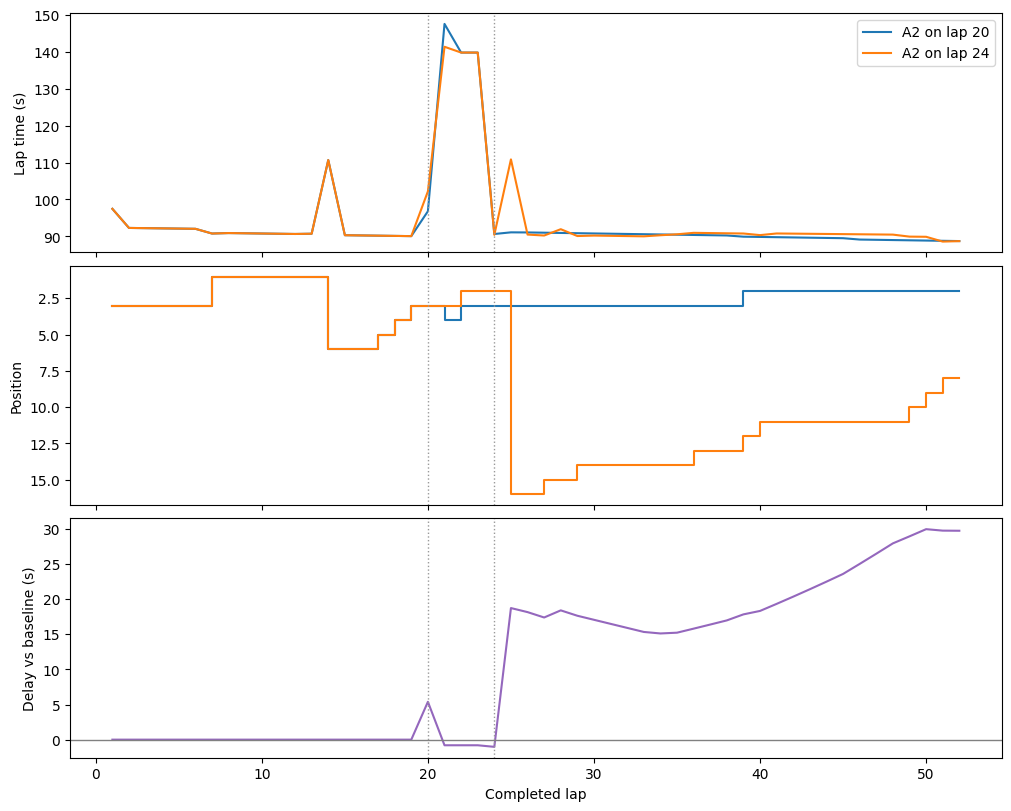

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, layout="constrained")
for race, label in [(baseline, "A2 on lap 20"), (delayed, "A2 on lap 24")]:
    axes[0].plot(laps, race.laptimes[1:, ver], label=label)
    axes[1].step(laps, race.positions[1:, ver], where="post")
axes[0].legend()
axes[0].set_ylabel("Lap time (s)")
axes[1].set_ylabel("Position")
axes[1].invert_yaxis()
axes[2].plot(laps, delayed.racetimes[1:, ver] - baseline.racetimes[1:, ver], color="tab:purple")
axes[2].axhline(0, color="0.5", linewidth=1)
axes[2].set_ylabel("Delay vs baseline (s)")
axes[2].set_xlabel("Completed lap")
for axis in axes:
    for pit_lap in (20, 24):
        axis.axvline(pit_lap, color="0.6", linestyle=":", linewidth=1)
plt.show()

A race strategist can use a matched pair like this to inspect the trade-off between tire degradation, pit loss under caution, and rejoining into traffic. The finish delta is conditional on the simulated Silverstone inputs. Historical classification and lap timing are separate checks, summarized in the [run notes](docs/silverstone_2019_run.md).